### Homework 07 - Least-squares method
Igor Di Tota

**Introduction**

In this exercise a set of $N$ measurements $(x_i, y_i, \sigma_i)$ is described with a polynomial series
$$
\mu(x; \mathbf{a}) = \sum_{k=0}^{M} a_k\, x^k ,
$$
where $M$ is the order of the polynomial and $\mathbf{a} = (a_0, \dots, a_M)$ are the $M+1$ free parameters.

Since the model is linear in the parameters, the least-squares method gives the best estimates of $\mathbf{a}$ and their covariance matrix, by solving a system of linear equations.

Assuming Gaussian measurement uncertainties and a correct model, the value of $\chi^2$ at the minimum follows a $\chi^2$ distribution with $N_{df} = N - (M+1)$ degrees of freedom, so it can be used to test whether the polynomial of order $M$ is consistent with the data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import os
os.makedirs("images", exist_ok=True)

# Data: x_i, y_i, sigma_i
x, y, sigma = np.loadtxt("07_homework.dat", unpack=True)
N = y.size

print(f"Number of points: N = {N}")
print(f"x range:     [{x.min():.4f}, {x.max():.4f}]")
print(f"sigma range: [{sigma.min():.4f}, {sigma.max():.4f}]")
print(f"sigma increasing with x: {np.all(np.diff(sigma) > 0)}")

Number of points: N = 24
x range:     [0.0250, 1.1750]
sigma range: [0.0207, 0.0498]
sigma increasing with x: True


### Data

The data set consists of $N = 24$ points. Each value $y_i$ is given with its uncertainty $\sigma_i$, which is not constant but increases with $x$, from about $0.021$ to $0.050$.
The measurements therefore have different weights in the fit, and each term of the $\chi^2$ must be divided by its own $\sigma_i^2$.

The dependence of $y$ on $x$ is clearly not linear. No model for this dependence is given, so polynomials of increasing order are tested.

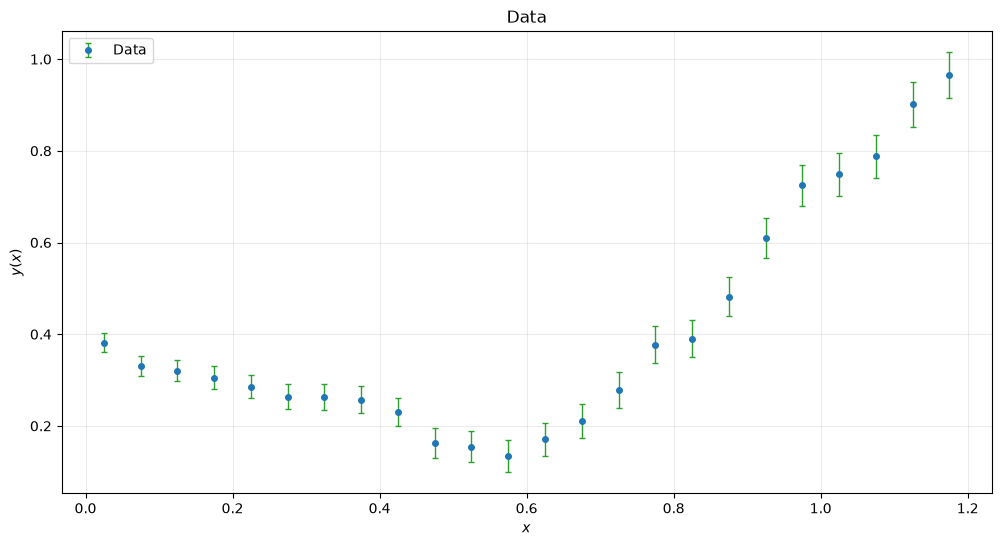

In [2]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, capsize=2, color="tab:blue", ecolor="tab:green", elinewidth=1, label="Data")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y(x)$")
ax.set_title("Data")
ax.legend()
ax.grid(alpha=0.3, color="silver")
fig.savefig("images/data.pdf", bbox_inches="tight")
plt.show()


### Linear regression

The model is linear in the parameters:
$$
\mu(x; \mathbf{a}) = \sum_{k=0}^{M} a_k f_k(x) \quad \text{with } f_k(x) = x^k.
$$
The best estimates of $\mathbf{a}$ correspond to the minimum of
$$
\chi^2(\mathbf{a}) = \sum_{i=1}^{N} \frac{\left(y_i - \sum_{k} a_k f_k(x_i)\right)^2}{\sigma_i^2} ,
$$
which, for Gaussian uncertainties, is equivalent to the maximum of the log-likelihood function $\ell = \ln L$, since $\chi^2 = -2\ell$.

Setting $\partial\chi^2/\partial a_l = 0$ for $l = 0, \dots, M$ gives a system of $M+1$ linear equations
$$
\sum_{k=0}^{M} \left( \sum_{i=1}^{N} \frac{f_l(x_i)\, f_k(x_i)}{\sigma_i^2} \right) a_k = \sum_{i=1}^{N} \frac{f_l(x_i)\, y_i}{\sigma_i^2} ,
$$
which can be written in matrix form as $\mathbb{A}\cdot\mathbf{a} = \mathbf{b}$, with
$$
\mathbb{A}_{lk} = \sum_{i=1}^{N} \frac{x_i^{\,l+k}}{\sigma_i^2} ,
\qquad
b_l = \sum_{i=1}^{N} \frac{x_i^{\,l}\, y_i}{\sigma_i^2} ,
\qquad
\mathbf{a} = \mathbb{A}^{-1} \cdot \mathbf{b} .
$$

The first derivatives of the $\chi^2$ are
$$
\frac{\partial\chi^2}{\partial a_l} = -2 \sum_{i=1}^{N} \frac{f_l(x_i)}{\sigma_i^2} \left( y_i - \sum_{k=0}^{M} a_k f_k(x_i) \right) ,
$$
and differentiating once more with respect to $a_k$,
$$
\frac{\partial^2\chi^2}{\partial a_l\, \partial a_k} = 2 \sum_{i=1}^{N} \frac{f_l(x_i)\, f_k(x_i)}{\sigma_i^2} = 2\,\mathbb{A}_{lk} .
$$
The second derivatives do not depend on $\mathbf{a}$: the $\chi^2$ is exactly a quadratic function of the parameters, so the parabolic approximation used in the maximum likelihood method to derive the covariance matrix is exact in this case, and

$$
\mathbb{C}_{\mathbf{a}} = \left(-\frac{\partial^2 \ell}{\partial a_l\, \partial a_k}\right)^{-1} = \left(\frac{1}{2}\frac{\partial^2\chi^2}{\partial a_l\, \partial a_k}\right)^{-1} = \mathbb{A}^{-1} .
$$

The quality of the fit is described by the value $\chi^2_{min}$ at the minimum which, if the model is correct, follows a $\chi^2$ distribution with $N_{df} = N - (M+1)$ degrees of freedom.

The p-value is the probability of obtaining a value equal to or larger than the observed one, if the model is correct:
$$
p = \int_{\chi^2_{min}}^{+\infty} f_{\chi^2}(t; N_{df})\, dt = 1 - P(\chi^2_{min}; N_{df}),
$$
where $f_{\chi^2}$ is the $\chi^2$ probability density and $P$ its cumulative distribution function.


### Implementation

The function `polynomial_fit` builds the matrix $\mathbb{A}$ and the vector $\mathbf{b}$ for a polynomial of order $M$, solves the system $\mathbb{A}\cdot\mathbf{a} = \mathbf{b}$ and returns the parameters $\mathbf{a}$, the covariance matrix $\mathbb{C}_{\mathbf{a}} = \mathbb{A}^{-1}$, the value $\chi^2_{min}$, the number of degrees of freedom $N_{df}$ and the p-value.

The system is solved with `np.linalg.solve` instead of computing $\mathbb{A}^{-1}\cdot\mathbf{b}$ explicitly, since for high polynomial orders the matrix $\mathbb{A}$ becomes ill-conditioned (the functions $x^k$ are strongly correlated on the interval of the data).

The p-value is computed as $1 - P(\chi^2_{min}; N_{df})$ with the cumulative distribution function `stats.chi2.cdf`; for very small p-values (below about $10^{-16}$) the result is rounded to zero, since $P(\chi^2_{min}; N_{df})$ cannot be distinguished from 1.


In [3]:
def polynomial_fit(M):
    "Least-squares fit of a polynomial of order M to the data (x, y, sigma)"
    A = np.empty((M + 1, M + 1))
    b = np.empty(M + 1)
    for l in range(M + 1):
        b[l] = np.sum(x**l * y / sigma**2)
        for k in range(M + 1):
            A[l, k] = np.sum(x**(l + k) / sigma**2)

    a = np.linalg.solve(A, b)                       # best estimates of the parameters
    cov = np.linalg.inv(A)                          # covariance matrix C_a = A^-1
    
    mu = sum(a[k] * x**k for k in range(M + 1))     # fitted values mu(x_i; a)
    
    chi2 = np.sum((y - mu)**2 / sigma**2)
    ndf = N - (M + 1)
    p = 1 - stats.chi2.cdf(chi2, ndf)
    return a, cov, chi2, ndf, p

# Fit of polynomials of increasing order
M_max = 8
results = {}
for M in range(M_max + 1):
    a, cov, chi2, ndf, p = polynomial_fit(M)
    results[M] = {"a": a, "cov": cov, "chi2": chi2, "ndf": ndf, "p": p}

print(f"{'M':>2} {'Npar':>4} {'chi2':>9} {'ndf':>4} {'chi2/ndf':>9} {'p-value':>10} {'Delta chi2':>11}")
for M, r in results.items():
    dchi2 = results[M - 1]["chi2"] - r["chi2"] if M > 0 else np.nan     # chi2 decrease w.r.t. order M-1
    print(f"{M:>2} {M + 1:>4} {r['chi2']:>9.2f} {r['ndf']:>4} {r['chi2'] / r['ndf']:>9.2f} {r['p']:>10.2e} {dchi2:>11.2f}")


 M Npar      chi2  ndf  chi2/ndf    p-value  Delta chi2
 0    1    767.52   23     33.37   0.00e+00         nan
 1    2    538.57   22     24.48   0.00e+00      228.96
 2    3     50.20   21      2.39   3.42e-04      488.36
 3    4     39.52   20      1.98   5.74e-03       10.68
 4    5     20.39   19      1.07   3.72e-01       19.14
 5    6     13.37   18      0.74   7.69e-01        7.01
 6    7      7.08   17      0.42   9.82e-01        6.29
 7    8      6.47   16      0.40   9.82e-01        0.61
 8    9      6.20   15      0.41   9.76e-01        0.28


### Fit results

The polynomials of order $M = 0, \dots, 8$ are fitted to the data and, for each order, the value $\chi^2_{min}$, the number of degrees of freedom $N_{df} = N - (M+1)$ and the p-value are computed.
The column $\Delta\chi^2$ is the decrease of $\chi^2_{min}$ with respect to the polynomial of order $M-1$, obtained by adding one parameter to the model.

The polynomials of order $M = 2, \dots, 6$ are compared with the data in the figure below.
The orders $M = 0$ and $M = 1$ are not shown, since they clearly cannot describe the data.

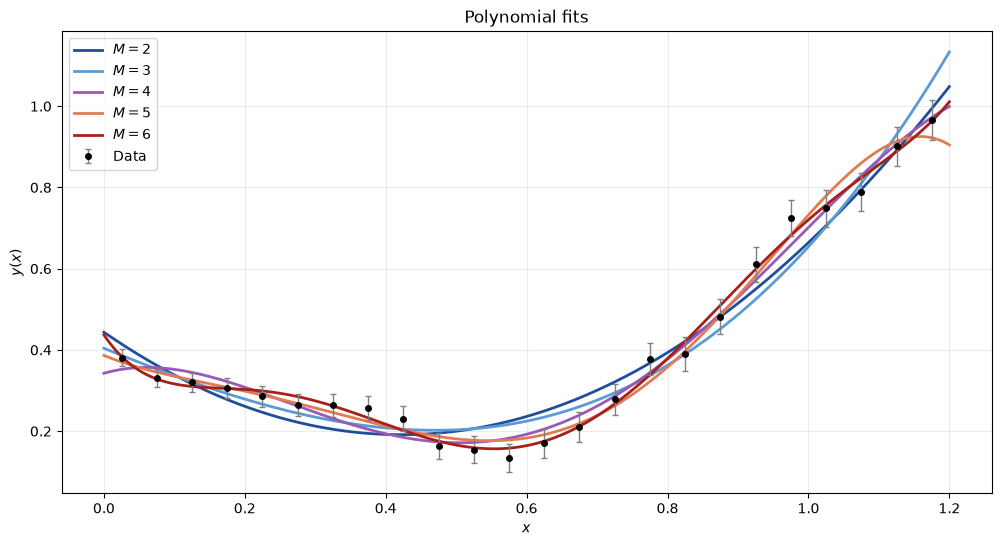

In [4]:
def polynomial(a, x):
    "Polynomial with coefficients a = (a_0, ..., a_M) evaluated at x"
    return sum(a[k] * x**k for k in range(a.size))


M_plot = [2, 3, 4, 5, 6]
x_fine = np.linspace(0, 1.2, 1000)
colors = ["#1f4e9c", "#5b9bd5", "#9b59b6", "#e07b54", "#a8201a"]

fig, ax = plt.subplots(figsize=(12, 6))
ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, capsize=2, color="black", ecolor="gray", elinewidth=1, label="Data", zorder=3)
for M, c in zip(M_plot, colors):
    r = results[M]
    ax.plot(x_fine, polynomial(r["a"], x_fine), color=c, lw=2, label=rf"$M = {M}$")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y(x)$")
ax.set_title("Polynomial fits")
ax.legend()
ax.grid(alpha=0.3, color="silver")
fig.savefig("images/fits.pdf", bbox_inches="tight")
plt.show()


### High order polynomials

The polynomials of order $M = 6, 7, 8$ are compared in the figure below.
In the range of the data the three curves are practically indistinguishable, consistently with the very small decrease of $\chi^2_{min}$ ($\Delta\chi^2 < 1$) obtained by adding the corresponding parameters.
The curves differ only at the edges of the interval, shown in the two zoomed panels: at the measurement points the differences between them are at most about half of the uncertainty $\sigma_i$, and they become larger only outside the range of the data ($x < 0.025$ and $x > 1.175$), where the polynomials are not constrained by any measurement.

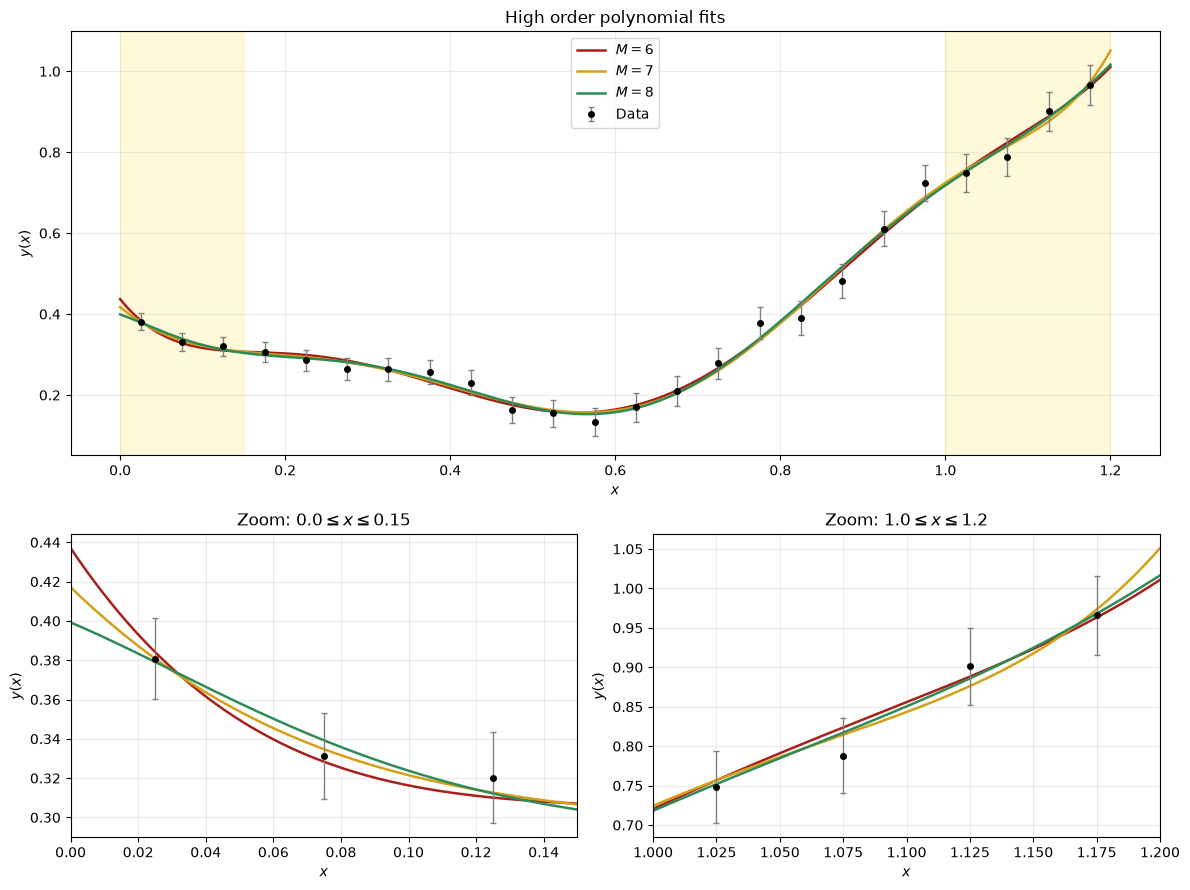

In [5]:
M_high = [6, 7, 8]
colors_high = ["#a8201a", "#d4a017", "#2e8b57"]
zooms = [(0.0, 0.15), (1.0, 1.2)]

fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.4, 1])
ax_main = fig.add_subplot(gs[0, :])
ax_zoom = [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]

for ax in [ax_main] + ax_zoom:
    ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, capsize=2, color="black", ecolor="gray", elinewidth=1, label="Data", zorder=3)
    for M, c in zip(M_high, colors_high):
        r = results[M]
        ax.plot(x_fine, polynomial(r["a"], x_fine), color=c, lw=1.8, label=rf"$M = {M}$")
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y(x)$")
    ax.grid(alpha=0.3, color="silver")

# Zoomed panels: y range adapted to the curves and to the data in the selected x range
for ax, (x_lo, x_hi) in zip(ax_zoom, zooms):
    in_range = (x_fine >= x_lo) & (x_fine <= x_hi)
    points = (x >= x_lo) & (x <= x_hi)
    curves = np.concatenate([polynomial(results[M]["a"], x_fine[in_range]) for M in M_high])
    y_lo = min(curves.min(), (y - sigma)[points].min())
    y_hi = max(curves.max(), (y + sigma)[points].max())
    pad = 0.05 * (y_hi - y_lo)
    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(y_lo - pad, y_hi + pad)
    ax.set_title(rf"Zoom: ${x_lo} \leq x \leq {x_hi}$")
    ax_main.axvspan(x_lo, x_hi, color="gold", alpha=0.15)     # zoomed region in the main panel

ax_main.set_title("High order polynomial fits")
ax_main.legend()
fig.tight_layout()
fig.savefig("images/fits_high_order.pdf", bbox_inches="tight")
plt.show()


### Normalized residuals

The agreement between the data and each fit is studied with the normalized residuals
$$
r_i = \frac{y_i - \mu(x_i; \mathbf{a})}{\sigma_i} ,
$$
whose sum of squares is $\chi^2_{min}$.
If the model is correct, the residuals fluctuate randomly around zero, with about 68% of them within $\pm 1$ and about 95% within $\pm 2$.
If the order of the polynomial is too low, the residuals deviate systematically from zero in some regions of $x$.
If the order is too high, the polynomial starts to follow the fluctuations of the data and the residuals become smaller than expected.

The residuals are shown for the orders $M = 3, 4, 5, 6$.

The code below prints, for each order:
- `max|r|`: the largest normalized residual in absolute value, $\max_i |r_i|$;
- `|r|<1` and `|r|<2`: the fraction of residuals with $|r_i| < 1$ and $|r_i| < 2$, to be compared with the expected values of about 0.68 and 0.95.



 M  max|r|  |r|<1  |r|<2
 3    2.61   0.54   0.92
 4    1.79   0.67   1.00
 5    1.53   0.83   1.00
 6    0.97   1.00   1.00


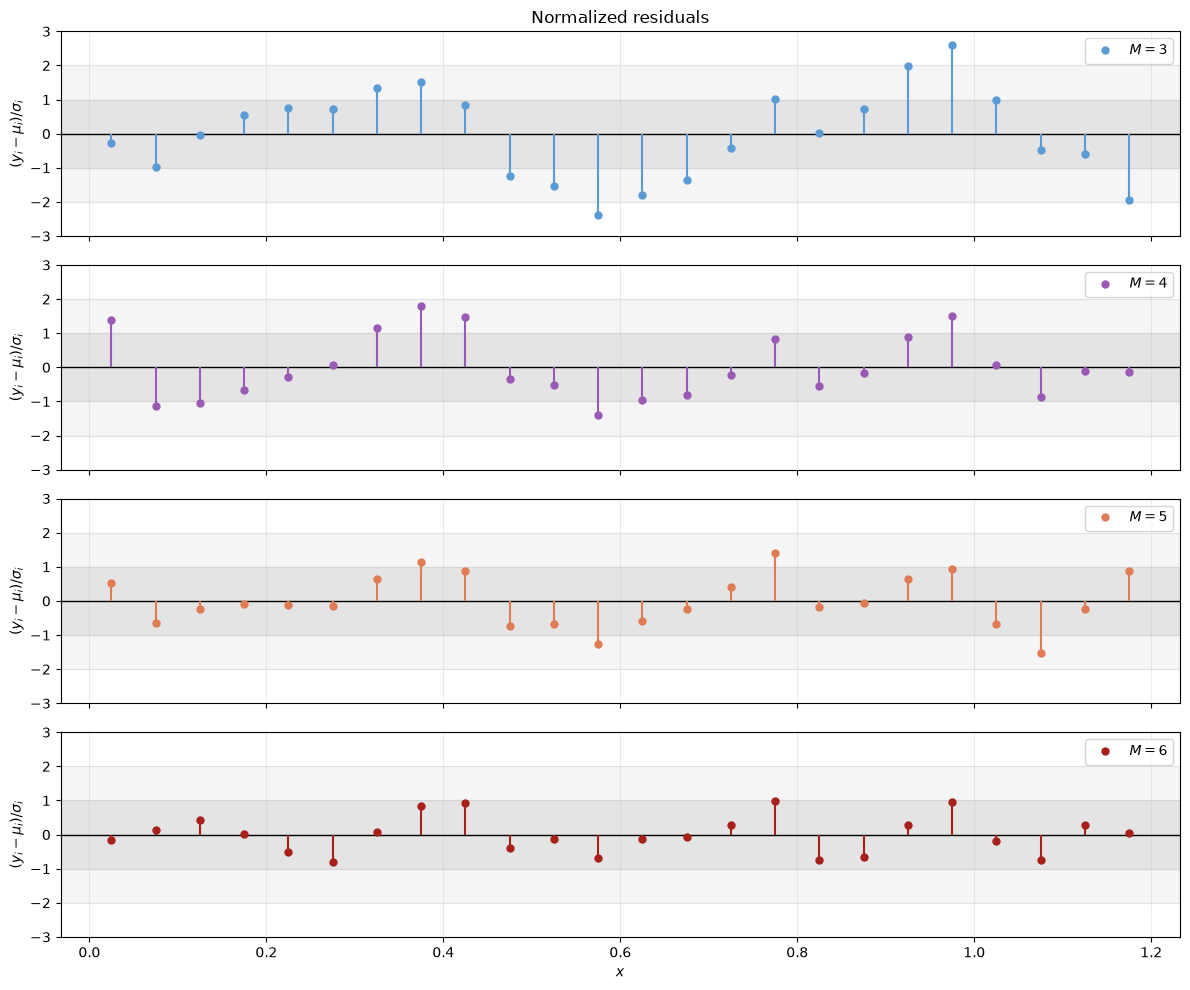

In [6]:
M_res = [3, 4, 5, 6]
colors_res = ["#5b9bd5", "#9b59b6", "#e07b54", "#a8201a"]

print(f"{'M':>2} {'max|r|':>7} {'|r|<1':>6} {'|r|<2':>6}")

fig, axes = plt.subplots(len(M_res), 1, figsize=(12, 10), sharex=True)
for ax, M, c in zip(axes, M_res, colors_res):
    r = (y - polynomial(results[M]["a"], x)) / sigma
    print(f"{M:>2} {np.abs(r).max():>7.2f} {np.mean(np.abs(r) < 1):>6.2f} {np.mean(np.abs(r) < 2):>6.2f}")

    ax.axhspan(-1, 1, color="silver", alpha=0.3)
    ax.axhspan(-2, 2, color="silver", alpha=0.15)
    ax.axhline(0, color="black", lw=1)
    ax.vlines(x, 0, r, color=c, lw=1.5)
    ax.plot(x, r, "o", color=c, ms=5, label=rf"$M = {M}$")
    ax.set_ylim(-3, 3)
    ax.set_ylabel(r"$(y_i - \mu_i)/\sigma_i$")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3, color="silver")

axes[-1].set_xlabel(r"$x$")
axes[0].set_title("Normalized residuals")
fig.tight_layout()
fig.savefig("images/residuals.pdf", bbox_inches="tight")
plt.show()


### Parameters and correlations

The uncertainties of the parameters are given by the diagonal elements of the covariance matrix, $\sigma(a_k) = \sqrt{(\mathbb{C}_{\mathbf{a}})_{kk}}$, and the correlation coefficients by
$$
\rho_{lk} = \frac{(\mathbb{C}_{\mathbf{a}})_{lk}}{\sigma(a_l)\, \sigma(a_k)} .
$$

When the order of the polynomial is increased from $M-1$ to $M$, the new parameter $a_M$ is added to the model.
If the polynomial of order $M-1$ already describes the data, the additional parameter is not needed and its fitted value is expected to be consistent with zero.
This is quantified by the significance of the last coefficient, i.e. its distance from zero in units of its uncertainty, $\hat a_M / \sigma(a_M)$: values of $|\hat a_M| / \sigma(a_M)$ of order 1 are expected if the parameter is not needed, while values of 3 or more indicate that $a_M$ is significantly different from zero.

For a model linear in the parameters, the significance of $a_M$ is directly related to the decrease of the $\chi^2$ obtained by adding it to the model.
Since the $\chi^2$ is exactly quadratic in the parameters, the $\chi^2$ minimized with respect to all the other parameters is, as a function of $a_M$ alone, a parabola with its minimum at $\hat a_M$ and increasing by 1 at $\hat a_M \pm \sigma(a_M)$:
$$
\chi^2(a_M) = \chi^2_{min}(M) + \left(\frac{a_M - \hat a_M}{\sigma(a_M)}\right)^2 .
$$
The polynomial of order $M-1$ corresponds to $a_M = 0$, therefore
$$
\Delta\chi^2 = \chi^2_{min}(M-1) - \chi^2_{min}(M) = \left(\frac{\hat a_M}{\sigma(a_M)}\right)^2 ,
$$
so a significant decrease of the $\chi^2$ corresponds to a value of $a_M$ significantly different from zero.
Since $\hat{\mathbf{a}}$ is a linear function of the Gaussian measurements $y_i$, the estimate $\hat a_M$ is Gaussian with standard deviation $\sigma(a_M)$.
If the parameter is not needed (true value $a_M = 0$), $\hat a_M / \sigma(a_M)$ follows a standard Gaussian distribution and $\Delta\chi^2$, its square, follows a $\chi^2$ distribution with one degree of freedom, with mean value 1: values $\Delta\chi^2 < 3.84$ are expected with 95% probability, and values $\Delta\chi^2 > 9$ only with 0.3% probability.
The p-value of $\Delta\chi^2$, computed with the $\chi^2$ distribution for one degree of freedom, gives the probability of a decrease equal to or larger than the observed one if the additional parameter is not needed.

Other indications that the polynomial has too many parameters are a strong increase of the values and of the uncertainties of the parameters, since the polynomial becomes a sum of large contributions cancelling each other, and correlations between the parameters approaching $\pm 1$.

The code below prints, for each order $M = 1, \dots, 8$:
- `a_M` and `sigma(a_M)`: the fitted value of the last coefficient $\hat a_M$ and its uncertainty $\sigma(a_M)$;
- `a_M/sigma`: the significance of the last coefficient, $\hat a_M / \sigma(a_M)$;
- `Delta chi2`: the decrease of the $\chi^2$ with respect to the polynomial of order $M-1$, $\Delta\chi^2 = \chi^2_{min}(M-1) - \chi^2_{min}(M)$;
- `p(Delta chi2)`: the p-value of $\Delta\chi^2$ for a $\chi^2$ distribution with one degree of freedom, $1 - P(\Delta\chi^2; 1)$;
- `max|rho|`: the largest correlation coefficient in absolute value between two different parameters, $\max_{l \neq k} |\rho_{lk}|$.

It then prints the parameters $\hat a_k \pm \sigma(a_k)$ of the polynomial of order $M = 4$, and shows the correlation matrices $\rho_{lk}$ for the orders $M = 3, 4, 5$.

 M        a_M  sigma(a_M)  a_M/sigma  Delta chi2  p(Delta chi2)  max|rho|
 1      0.300       0.020      15.13      228.96       0.00e+00    0.7898
 2      1.416       0.064      22.10      488.36       0.00e+00    0.9596
 3      0.694       0.212       3.27       10.68       1.08e-03    0.9839
 4     -3.121       0.713      -4.37       19.14       1.22e-05    0.9915
 5     -6.414       2.422      -2.65        7.01       8.10e-03    0.9948
 6     20.877       8.321       2.51        6.29       1.21e-02    0.9965
 7     22.589      28.969       0.78        0.61       4.36e-01    0.9975
 8    -53.882     102.394      -0.53        0.28       5.99e-01    0.9982

Parameters for M = 4:
  a_0 =    0.342 +- 0.024
  a_1 =    0.500 +- 0.322
  a_2 =   -4.787 +- 1.209
  a_3 =    7.767 +- 1.631
  a_4 =   -3.121 +- 0.713


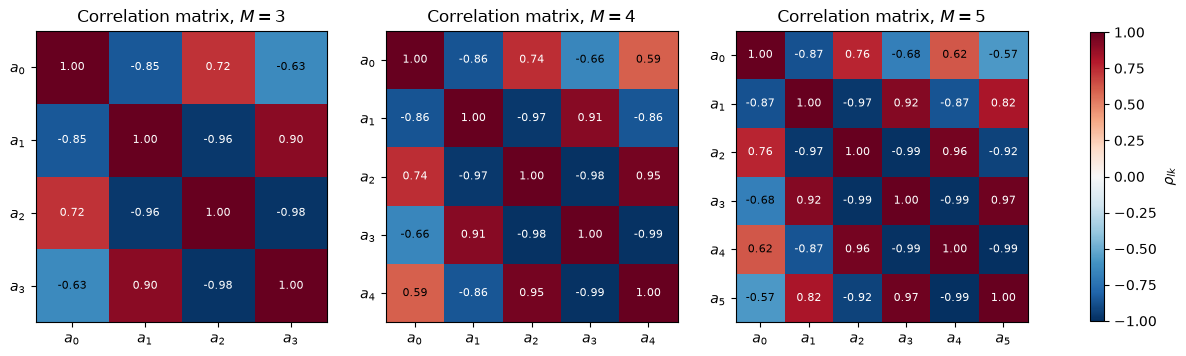

In [7]:
for M, r in results.items():
    r["err"] = np.sqrt(np.diag(r["cov"]))                    # parameter uncertainties sigma(a_k)
    r["corr"] = np.empty((M + 1, M + 1))                     # correlation matrix rho_lk
    for l in range(M + 1):
        for k in range(M + 1):
            r["corr"][l, k] = r["cov"][l, k] / (r["err"][l] * r["err"][k])

print(f"{'M':>2} {'a_M':>10} {'sigma(a_M)':>11} {'a_M/sigma':>10} {'Delta chi2':>11} {'p(Delta chi2)':>14} {'max|rho|':>9}")
for M in range(1, M_max + 1):
    r = results[M]
    signif = r["a"][-1] / r["err"][-1]                                   # significance of the last coefficient
    dchi2 = results[M - 1]["chi2"] - r["chi2"]
    p_dchi2 = 1 - stats.chi2.cdf(dchi2, 1)
    max_rho = np.abs(r["corr"][np.triu_indices(M + 1, k=1)]).max()       # largest correlation between different parameters
    print(f"{M:>2} {r['a'][-1]:>10.3f} {r['err'][-1]:>11.3f} {signif:>10.2f} {dchi2:>11.2f} {p_dchi2:>14.2e} {max_rho:>9.4f}")

# Parameters of the polynomial of order 4
M_best = 4
r = results[M_best]
print(f"\nParameters for M = {M_best}:")
for k in range(M_best + 1):
    print(f"  a_{k} = {r['a'][k]:8.3f} +- {r['err'][k]:.3f}")

# Correlation matrices
M_corr = [3, 4, 5]
fig, axes = plt.subplots(1, len(M_corr), figsize=(16, 5))
for ax, M in zip(axes, M_corr):
    corr = results[M]["corr"]
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    for l in range(M + 1):
        for k in range(M + 1):
            ax.text(k, l, f"{corr[l, k]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(corr[l, k]) > 0.7 else "black")
    ax.set_xticks(range(M + 1), [rf"$a_{k}$" for k in range(M + 1)])
    ax.set_yticks(range(M + 1), [rf"$a_{k}$" for k in range(M + 1)])
    ax.set_title(rf"Correlation matrix, $M = {M}$")
fig.colorbar(im, ax=axes, shrink=0.75, label=r"$\rho_{lk}$")
fig.savefig("images/correlations.pdf", bbox_inches="tight")
plt.show()


### Conclusions

Polynomials of order $M = 0, \dots, 8$ were fitted to the $N = 24$ data points with the linear least-squares method.
For the two orders required by the exercise the results are:
- $M = 3$: $\chi^2_{min}/N_{df} = 39.5/20$, p-value $= 5.7 \cdot 10^{-3}$;
- $M = 4$: $\chi^2_{min}/N_{df} = 20.4/19$, p-value $= 0.37$.

The polynomial of order $M = 4$ is adequate for the description of the data, for the following reasons.

Polynomials of order $M \leq 3$ are excluded.
The p-value of the polynomial of order 3 is below 1%, and the ones of lower orders are even smaller.
The normalized residuals of the cubic fit show a systematic deviation from zero, with only 54% of the points within $\pm 1$ (instead of about 68%) and a largest residual of 2.6.

The polynomial of order $M = 4$ describes the data well.
The p-value is 0.37 and $\chi^2_{min}/N_{df} = 1.07$, as expected for a correct model.
The residuals are randomly distributed around zero, with 67% of them within $\pm 1$ and all of them within $\pm 2$.
The coefficient added with respect to the cubic polynomial, $a_4 = -3.12 \pm 0.71$, differs from zero by 4.4 standard deviations, corresponding to a decrease of the $\chi^2$ by $\Delta\chi^2 = 19.1$: if the additional parameter were not needed, a decrease at least this large would be obtained with a probability of only $1.2 \cdot 10^{-5}$.

The additional parameters of the polynomials of order $M = 5$ and $M = 6$ are not significant enough.
These orders still reduce the $\chi^2$ by $\Delta\chi^2 = 7.0$ and $6.3$, with p-values of about 1%, which would be considered significant at the 95% confidence level.
However, the corresponding coefficients differ from zero only by 2.6 and 2.5 standard deviations, below the threshold of 3 standard deviations adopted for a significant parameter; moreover, several orders have been tested, which increases the probability that one of them shows a fluctuation of this size.
At the same time, the fits become too good: $\chi^2_{min}/N_{df}$ decreases to 0.74 for $M = 5$ and 0.42 for $M = 6$.
The residuals show the same trend: the fraction within $\pm 1$ increases from 67% for $M = 4$, in agreement with the expected 68%, to 83% for $M = 5$ and 100% for $M = 6$, while about one third of the residuals are expected outside this range.
For $M = 6$ the probability of obtaining a $\chi^2$ as small as the observed one is only $1 - 0.982 = 0.018$.
This indicates that the polynomial starts to follow the statistical fluctuations of the measurements instead of the underlying dependence.

The parameters become strongly correlated and poorly determined.
The correlation matrices show an alternating pattern: adjacent coefficients $a_k$ and $a_{k+1}$ are strongly anti-correlated, with $\rho$ between $-0.85$ and $-0.99$, while coefficients two orders apart are positively correlated.
This happens because the functions $x^k$ and $x^{k+1}$ are very similar on the interval of the data, so that an increase of one coefficient is compensated by a decrease of the next one.
The fitted parameters already have alternating signs and large values for $M = 4$, and the polynomial is a sum of large contributions cancelling each other.
This effect grows with the order: the uncertainty of the last coefficient increases from 0.71 for $M = 4$ to 2.4, 8.3 and 29 for $M = 5, 6, 7$, and the correlations approach $\pm 1$.

Higher orders do not bring any improvement.
For $M = 7$ and $M = 8$ the decrease of the $\chi^2$ is below 1, as expected for parameters that are not needed, the last coefficients are consistent with zero, and the fitted curves cannot be distinguished from the one of order 6 in the range of the data.

The polynomial of order $M = 4$ is therefore the simplest one that is consistent with the data and whose parameters are all needed. The best estimates of its parameters are
$$
a_0 = 0.342 \pm 0.024, \quad
a_1 = 0.50 \pm 0.32, \quad
a_2 = -4.8 \pm 1.2, \quad
a_3 = 7.8 \pm 1.6, \quad
a_4 = -3.12 \pm 0.71,
$$
with the strong correlations shown in the correlation matrix.

### Final result

The data are shown below together with the polynomial of order $M = 4$, chosen as the adequate description of the data.
The curve is drawn only in the range of the measurements.

The uncertainty of the fitted curve at a given $x$ is obtained by propagating the covariance matrix of the parameters.
Since $\mu(x; \mathbf{a}) = \sum_k a_k x^k$ is linear in the parameters, the propagation is exact:
$$
\sigma_\mu^2(x) = \sum_{l=0}^{M} \sum_{k=0}^{M} x^{l}\, x^{k}\, (\mathbb{C}_{\mathbf{a}})_{lk} .
$$
The band $\mu(x) \pm \sigma_\mu(x)$ is shown in the figure.


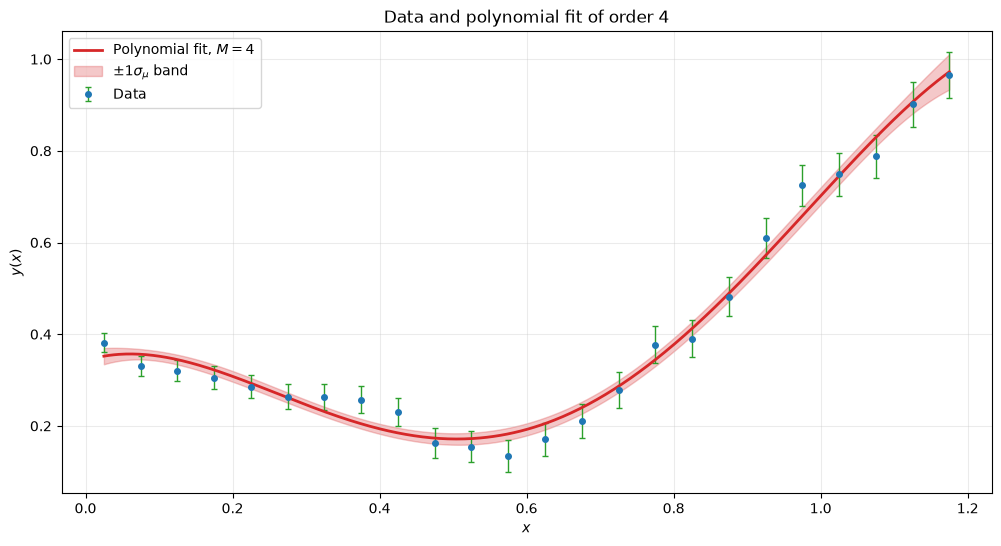

In [8]:
r = results[M_best]
x_data_range = np.linspace(x.min(), x.max(), 500)
mu_fit = polynomial(r["a"], x_data_range)

# Uncertainty of the fitted curve from the covariance matrix of the parameters
var_mu = np.zeros_like(x_data_range)
for l in range(M_best + 1):
    for k in range(M_best + 1):
        var_mu += x_data_range**l * x_data_range**k * r["cov"][l, k]
sigma_mu = np.sqrt(var_mu)

fig, ax = plt.subplots(figsize=(12, 6))
ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, capsize=2, color="tab:blue", ecolor="tab:green", elinewidth=1, label="Data")
ax.plot(x_data_range, mu_fit, color="tab:red", lw=2, label=rf"Polynomial fit, $M = {M_best}$")
ax.fill_between(x_data_range, mu_fit - sigma_mu, mu_fit + sigma_mu, color="tab:red", alpha=0.25, label=r"$\pm 1\sigma_\mu$ band")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y(x)$")
ax.set_title("Data and polynomial fit of order 4")
ax.legend()
ax.grid(alpha=0.3, color="silver")
fig.savefig("images/final_fit.pdf", bbox_inches="tight")
plt.show()
